# Q2 — Regression Models on the Parkinson's Telemonitoring Dataset
**IIIT Sri City — Machine Learning Assignment**

| Item | Choice |
|---|---|
| Dataset | UCI *Parkinsons Telemonitoring* (id 189) — 5,875 voice recordings from **42 patients** |
| Target | `total_UPDRS` (clinician's total Parkinson's severity score, 0–176 scale) |
| Inputs | 19 features: `age`, `sex`, `test_time` and 16 voice measures (jitter, shimmer, NHR, HNR, RPDE, DFA, PPE) |
| Models | (a) Linear regression with **gradient descent** (own implementation), (b) Polynomial regression, (c) Ridge & Lasso with CV-selected regularisation |
| Metrics | MSE, RMSE, R² (and Pearson R, in case "R" in the brief means correlation) |

### The 4 design decisions that matter most (viva-critical)
1. **Patients, not rows, are the independent units.** ~140 recordings per patient are near-duplicates of each other (same age, sex, similar voice). A *random* row split puts the same patient in train and test and gives over-optimistic scores. Our **primary evaluation uses a subject-wise split** (`GroupShuffleSplit`, `GroupKFold`): no patient appears on both sides. We also run the random split once, to *quantify* how much it inflates performance.
2. **No leakage from other label columns.** `motor_UPDRS` is the sibling target (strongly correlated with `total_UPDRS`) and `subject#` is an ID. Both are excluded from the inputs.
3. **Strong multicollinearity is built into the data** (e.g. `Jitter:DDP` = 3 × `Jitter:RAP` exactly; `Shimmer:DDA` = 3 × `Shimmer:APQ3`). That is the textbook motivation for Ridge/Lasso, and we prove it with VIF values.
4. **We do not expect a high R².** Voice features alone are weak predictors *across patients*. We report what we get and compare against a **mean-predictor baseline** (R² = 0 by definition) so results can be interpreted honestly.

In [1]:
# ---------------------------------------------------------------------------
# 0. Imports, configuration, reproducibility
# ---------------------------------------------------------------------------
import os, random, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import clone

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# project root = parent of notebooks/ (works whether Jupyter starts in notebooks/ or in the project root)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
FIG_DIR, RES_DIR, DATA_DIR = f"{ROOT}/figures/q2", f"{ROOT}/results", f"{ROOT}/data"
for d in (FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

TARGET = "total_UPDRS"
VOICE_ONLY = False          # True -> drop age, sex, test_time and use only the 16 voice measures

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")

## 1. Load the data
`ucimlrepo` first; if there is no internet, fall back to `data/parkinsons_updrs.data` (a CSV with a header row, from the UCI zip).

In [2]:
def load_parkinsons():
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=189)
        df = d.data.original.copy()
        src = "ucimlrepo (UCI id=189)"
    except Exception as e:
        print(f"[info] ucimlrepo unavailable ({type(e).__name__}); using local file in data/")
        path = f"{DATA_DIR}/parkinsons_updrs.data"
        if not os.path.exists(path):
            raise FileNotFoundError("Put parkinsons_updrs.data (from the UCI zip) into data/")
        df = pd.read_csv(path)
        src = path
    df = df.rename(columns={"subject#": "subject"})
    need = {"subject", "age", "sex", "test_time", "motor_UPDRS", "total_UPDRS", "Jitter(%)", "PPE"}
    assert need <= set(df.columns), f"Unexpected columns: {list(df.columns)}"
    return df.reset_index(drop=True), src

df, source = load_parkinsons()
print("Loaded from:", source, "| shape:", df.shape, "| patients:", df["subject"].nunique())
print("Missing values:", int(df.isna().sum().sum()))

DROP = ["subject", "motor_UPDRS", "total_UPDRS"]              # ID + both targets are never inputs
FEATURES = [c for c in df.columns if c not in DROP]
if VOICE_ONLY:
    FEATURES = [c for c in FEATURES if c not in ("age", "sex", "test_time")]
print(f"{len(FEATURES)} input features:", FEATURES)
X_all, y_all, groups_all = df[FEATURES], df[TARGET], df["subject"].values
df.head()

Loaded from: ucimlrepo (UCI id=189) | shape: (5875, 22) | patients: 42
Missing values: 0
19 input features: ['age', 'sex', 'test_time', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']


,subject,age,sex,test_time,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,...,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE,motor_UPDRS,total_UPDRS
0,1,72,0,5.6431,0.00662,0.000034,0.00401,0.00317,0.01204,0.02565,...,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006,28.199,34.398
1,1,72,0,12.6660,0.00300,0.000017,0.00132,0.00150,0.00395,0.02024,...,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810,28.447,34.894
2,1,72,0,19.6810,0.00481,0.000025,0.00205,0.00208,0.00616,0.01675,...,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014,28.695,35.389
3,1,72,0,25.6470,0.00528,0.000027,0.00191,0.00264,0.00573,0.02309,...,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277,28.905,35.810
4,1,72,0,33.6420,0.00335,0.000020,0.00093,0.00130,0.00278,0.01703,...,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361,29.187,36.375


## 2. Exploratory data analysis
We look at (i) the target, (ii) how many recordings each patient contributes, (iii) correlations, and (iv) **variance inflation factors (VIF)** — VIF > 10 is the usual warning sign of multicollinearity.

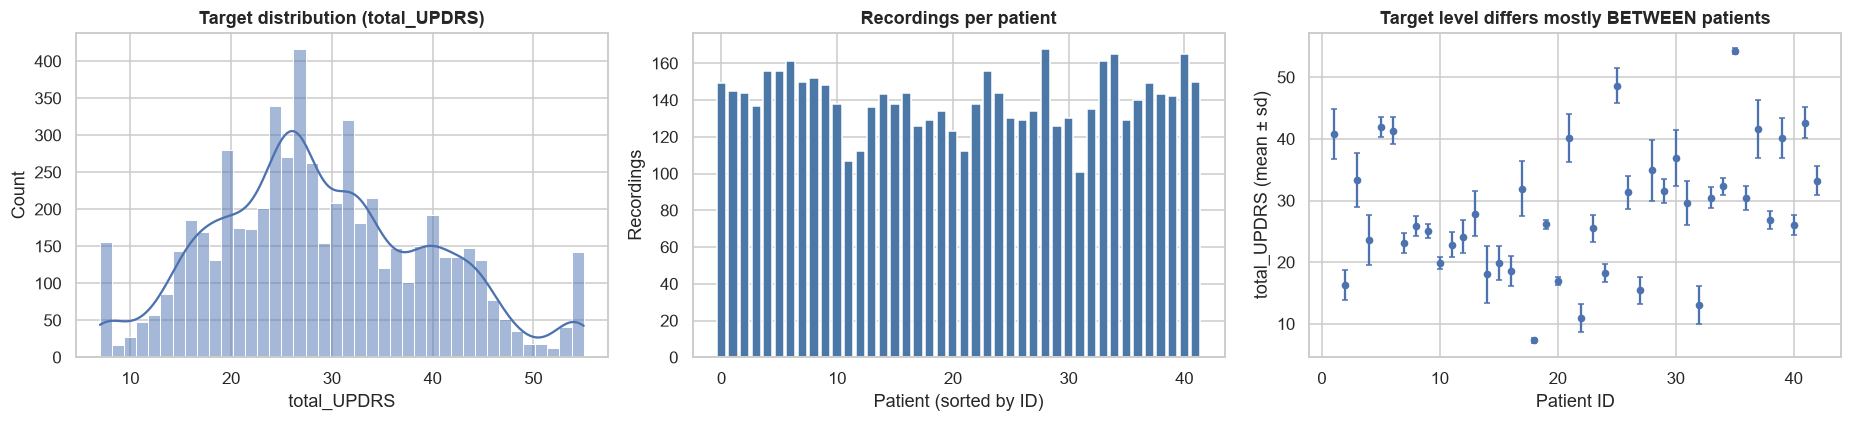

Mean within-patient variance of total_UPDRS: 7.9   |   variance of patient means: 109.1


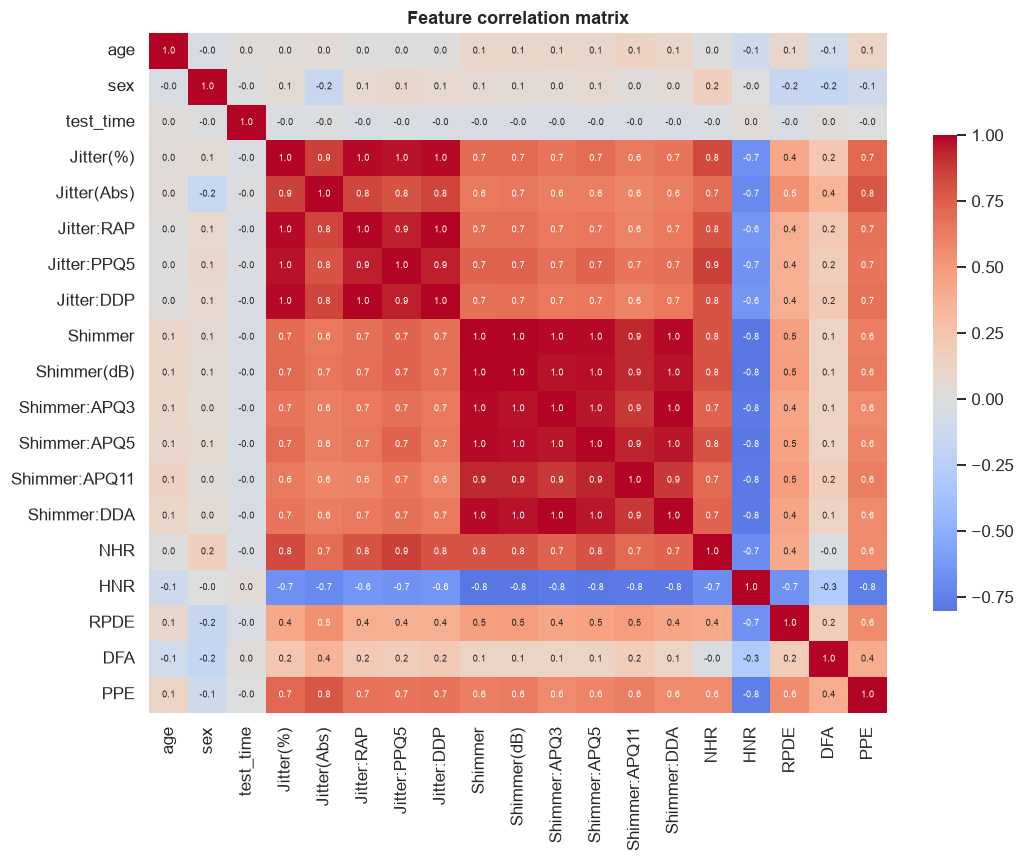

Jitter:DDP / Jitter:RAP: mean ratio = 3.0001, sd = 0.00470  -> (almost) exact multiple
Shimmer:DDA / Shimmer:APQ3: mean ratio = 3.0000, sd = 0.00084  -> (almost) exact multiple


,VIF
Shimmer:APQ3,1000000.0
Jitter:DDP,1000000.0
Jitter:RAP,1000000.0
Shimmer:DDA,1000000.0
Shimmer,173.5
Jitter(%),89.0
Shimmer(dB),76.9
Shimmer:APQ5,52.6
Jitter:PPQ5,31.0
Shimmer:APQ11,15.3


10 of 19 features have VIF > 10  ->  OLS coefficients will be unstable; regularisation is justified.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(y_all, bins=40, kde=True, ax=axes[0]); axes[0].set_title(f"Target distribution ({TARGET})")
cnt = df.groupby("subject").size()
axes[1].bar(range(len(cnt)), cnt.values, color="#4C78A8"); axes[1].set_title("Recordings per patient"); axes[1].set_xlabel("Patient (sorted by ID)"); axes[1].set_ylabel("Recordings")
means = df.groupby("subject")[TARGET].agg(["mean", "std"])
axes[2].errorbar(means.index, means["mean"], yerr=means["std"], fmt="o", ms=4, capsize=2)
axes[2].set_title("Target level differs mostly BETWEEN patients"); axes[2].set_xlabel("Patient ID"); axes[2].set_ylabel(f"{TARGET} (mean ± sd)")
plt.tight_layout(); savefig("01_eda_target_and_patients"); plt.show()

within = df.groupby("subject")[TARGET].var().mean(); between = df.groupby("subject")[TARGET].mean().var()
print(f"Mean within-patient variance of {TARGET}: {within:.1f}   |   variance of patient means: {between:.1f}")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(X_all.corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 6}, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Feature correlation matrix"); plt.tight_layout(); savefig("02_corr_heatmap"); plt.show()

# exact-multiple features
for a, b in [("Jitter:DDP", "Jitter:RAP"), ("Shimmer:DDA", "Shimmer:APQ3")]:
    if a in df and b in df:
        print(f"{a} / {b}: mean ratio = {(df[a] / df[b]).mean():.4f}, sd = {(df[a] / df[b]).std():.5f}  -> (almost) exact multiple")

def vif_table(Xdf):
    Xs = StandardScaler().fit_transform(Xdf); out = {}
    for j, c in enumerate(Xdf.columns):
        others = np.delete(Xs, j, axis=1)
        r2 = LinearRegression().fit(others, Xs[:, j]).score(others, Xs[:, j])
        out[c] = min(1 / max(1 - r2, 1e-12), 1e6)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

vif = vif_table(X_all)
display(vif.round(1).to_frame().head(12))
print(f"{(vif > 10).sum()} of {len(vif)} features have VIF > 10  ->  OLS coefficients will be unstable; regularisation is justified.")
vif.round(2).to_csv(f"{RES_DIR}/q2_vif.csv")

## 3. Train / test splits
* **Primary — subject-wise 80/20**: whole patients are assigned to train or test (`GroupShuffleSplit`). All tuning uses `GroupKFold` on the training patients only.
* **Comparison — random 80/20 rows**: used *only* in Section 9 to show leakage.

With 42 patients the test set holds ~8 patients, so a single split is noisy; Section 10 therefore repeats the evaluation with 5-fold `GroupKFold` over all patients.

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, te_idx = next(gss.split(X_all, y_all, groups_all))
Xtr, Xte, ytr, yte = X_all.iloc[tr_idx], X_all.iloc[te_idx], y_all.iloc[tr_idx].values, y_all.iloc[te_idx].values
gtr, gte = groups_all[tr_idx], groups_all[te_idx]
assert set(gtr).isdisjoint(gte), "patient leakage!"
print(f"Subject-wise split → train: {len(Xtr)} rows / {len(set(gtr))} patients | test: {len(Xte)} rows / {len(set(gte))} patients")

rtr_idx, rte_idx = train_test_split(np.arange(len(df)), test_size=0.20, random_state=SEED)   # leaky comparison split
print(f"Random-row split   → train: {len(rtr_idx)} | test: {len(rte_idx)} | patients present in BOTH: {len(set(groups_all[rtr_idx]) & set(groups_all[rte_idx]))}")

GKF = GroupKFold(n_splits=5)       # used for ALL tuning (on training patients only)

Subject-wise split → train: 4640 rows / 33 patients | test: 1235 rows / 9 patients
Random-row split   → train: 4700 | test: 1175 | patients present in BOTH: 42


## 4. Evaluation helpers and the mean-predictor baseline
* **MSE** = mean of squared errors (units², penalises large errors)
* **RMSE** = √MSE (same units as the target → interpretable)
* **R²** = 1 − SS_res/SS_tot — fraction of variance explained (0 = as good as predicting the mean; negative = worse than the mean)
* **R (Pearson)** = correlation between predictions and truth, reported as an extra because the brief only says "R".

In [5]:
def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    r = np.corrcoef(y_true, y_pred)[0, 1] if np.std(y_pred) > 0 else np.nan
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred), "R (Pearson)": r}

ROWS = {}     # model name -> {"train": metrics, "test": metrics, "pred_test": ...}
def record(name, model_or_none, ytr_pred, yte_pred, extra=None):
    ROWS[name] = {"train": reg_metrics(ytr, ytr_pred), "test": reg_metrics(yte, yte_pred), "pred_test": np.asarray(yte_pred), "extra": extra or {}}
    t = ROWS[name]["test"]
    print(f"[{name}]  test RMSE={t['RMSE']:.3f}  R²={t['R2']:.3f}   (train RMSE={ROWS[name]['train']['RMSE']:.3f}, R²={ROWS[name]['train']['R2']:.3f})")

base = DummyRegressor(strategy="mean").fit(Xtr, ytr)
record("Baseline (mean)", base, base.predict(Xtr), base.predict(Xte))

[Baseline (mean)]  test RMSE=9.467  R²=-0.082   (train RMSE=11.021, R²=0.000)


## 5. Model (a) — Linear regression with gradient descent (implemented from scratch)
**Model:** ŷ = Xw + b. **Loss:** we minimise **½·MSE**, J(w,b) = (1/2n) Σ (ŷᵢ − yᵢ)². Its gradients are
∂J/∂w = (1/n) Xᵀ(ŷ − y)  and  ∂J/∂b = (1/n) Σ(ŷᵢ − yᵢ).
**Update rule (batch GD):** w ← w − η·∂J/∂w, b ← b − η·∂J/∂b, with learning rate η.
**Why standardise first:** the features live on wildly different scales (`test_time` ~ 0–215, `Jitter(Abs)` ~ 1e-5). Without scaling the loss surface is a very elongated valley and GD needs a tiny η or diverges. We demonstrate this below.
**Convergence:** GD is stable only if η < 2/λ_max(Hessian). A learning rate that is too large makes the loss *grow* (divergence); too small is very slow.

η=0.001  iterations run=3000  final train MSE=97.748  diverged=False


η=0.01   iterations run=3000  final train MSE=94.104  diverged=False


η=0.1    iterations run=3000  final train MSE=93.958  diverged=False
η=0.5    iterations run=11    final train MSE=43918118648868.445  diverged=True
η=1.5    iterations run=7     final train MSE=416101662595540.875  diverged=True


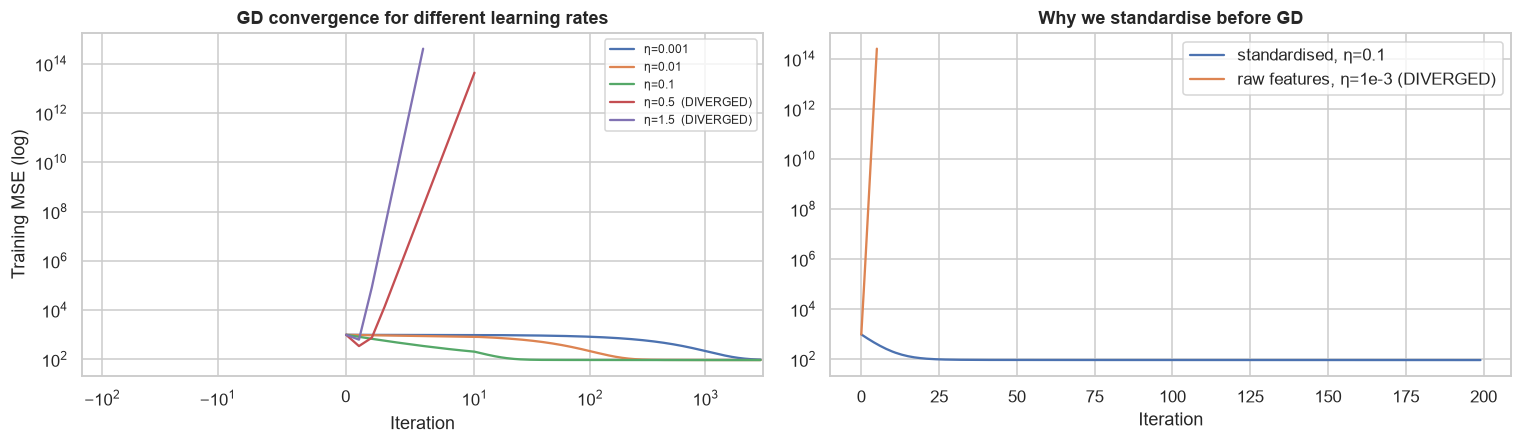

In [6]:
class LinearRegressionGD:
    """Batch gradient-descent linear regression: minimises 1/(2n)·Σ(Xw+b−y)²."""
    def __init__(self, lr=0.1, n_iter=20000, tol=1e-12):
        self.lr, self.n_iter, self.tol = lr, n_iter, tol
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float); n, d = X.shape
        self.w_, self.b_ = np.zeros(d), 0.0
        self.loss_, self.diverged_ = [], False
        for it in range(self.n_iter):
            err = X @ self.w_ + self.b_ - y
            mse = float(np.mean(err ** 2))
            if not np.isfinite(mse) or mse > 1e15:              # divergence guard
                self.diverged_ = True; break
            self.loss_.append(mse)
            if it > 0 and abs(self.loss_[-2] - mse) < self.tol:  # converged
                break
            self.w_ -= self.lr * (X.T @ err) / n
            self.b_ -= self.lr * err.mean()
        self.n_iter_ = len(self.loss_)
        return self
    def predict(self, X):
        return np.asarray(X, float) @ self.w_ + self.b_

scaler = StandardScaler().fit(Xtr)                    # fitted on TRAIN only
Ztr, Zte = scaler.transform(Xtr), scaler.transform(Xte)

# (i) learning-rate study on standardised data
lrs = [0.001, 0.01, 0.1, 0.5, 1.5]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for lr in lrs:
    m = LinearRegressionGD(lr=lr, n_iter=3000, tol=0).fit(Ztr, ytr)
    lab = f"η={lr}" + ("  (DIVERGED)" if m.diverged_ else "")
    axes[0].plot(m.loss_, label=lab)
    print(f"η={lr:<6} iterations run={m.n_iter_:<5} final train MSE={m.loss_[-1]:.3f}  diverged={m.diverged_}")
axes[0].set_yscale("log"); axes[0].set_xscale("symlog", linthresh=10); axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Training MSE (log)")
axes[0].set_title("GD convergence for different learning rates"); axes[0].legend(fontsize=8)

# (ii) why scaling matters: same GD on RAW features
raw = LinearRegressionGD(lr=1e-3, n_iter=200, tol=0).fit(Xtr.values, ytr)
good = LinearRegressionGD(lr=0.1, n_iter=200, tol=0).fit(Ztr, ytr)
axes[1].plot(good.loss_, label="standardised, η=0.1")
axes[1].plot(raw.loss_ if not raw.diverged_ else raw.loss_ + [np.nan], label=f"raw features, η=1e-3 ({'DIVERGED' if raw.diverged_ else 'slow'})")
axes[1].set_yscale("log"); axes[1].set_title("Why we standardise before GD"); axes[1].set_xlabel("Iteration"); axes[1].legend()
plt.tight_layout(); savefig("03_gd_learning_rates_and_scaling"); plt.show()

GD finished after 50000 iterations (diverged=False), final train MSE = 93.9449
Closed-form OLS train MSE = 93.8967  | GD train MSE = 93.9449
max |prediction difference| GD vs OLS on test = 0.6277


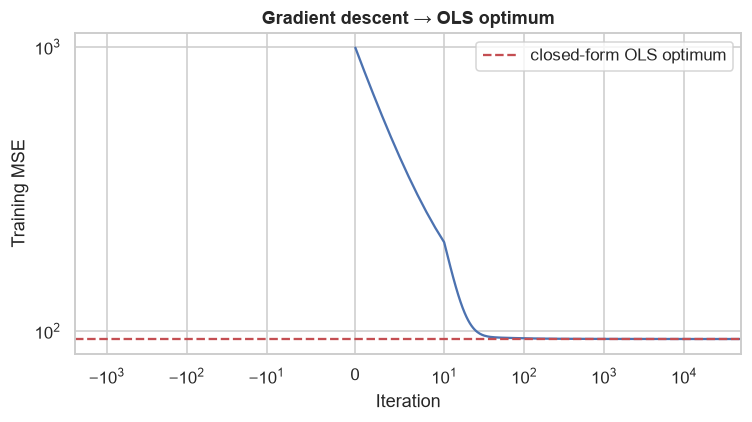

[Linear regression (GD)]  test RMSE=11.434  R²=-0.578   (train RMSE=9.693, R²=0.227)
[Linear regression (closed form)]  test RMSE=11.441  R²=-0.580   (train RMSE=9.690, R²=0.227)


In [7]:
# Final GD model: eta chosen from the study above (largest stable value)
gd = LinearRegressionGD(lr=0.1, n_iter=50000, tol=1e-13).fit(Ztr, ytr)
print(f"GD finished after {gd.n_iter_} iterations (diverged={gd.diverged_}), final train MSE = {gd.loss_[-1]:.4f}")

# Sanity check against the closed-form solution (normal equation via least squares)
ols = LinearRegression().fit(Ztr, ytr)
print(f"Closed-form OLS train MSE = {mean_squared_error(ytr, ols.predict(Ztr)):.4f}  | GD train MSE = {gd.loss_[-1]:.4f}")
print(f"max |prediction difference| GD vs OLS on test = {np.abs(gd.predict(Zte) - ols.predict(Zte)).max():.4f}")

plt.figure(figsize=(7, 4)); plt.plot(gd.loss_); plt.axhline(mean_squared_error(ytr, ols.predict(Ztr)), color="r", ls="--", label="closed-form OLS optimum")
plt.yscale("log"); plt.xscale("symlog", linthresh=10); plt.xlabel("Iteration"); plt.ylabel("Training MSE"); plt.title("Gradient descent → OLS optimum"); plt.legend()
plt.tight_layout(); savefig("04_gd_final_loss"); plt.show()

record("Linear regression (GD)", gd, gd.predict(Ztr), gd.predict(Zte), {"lr": 0.1, "iterations": gd.n_iter_})
record("Linear regression (closed form)", ols, ols.predict(Ztr), ols.predict(Zte))

## 6. Model (b) — Polynomial regression, overfitting and underfitting
Polynomial regression is *still linear regression*, but on expanded features (x, x², x·z, …). The **degree** controls model complexity:
* degree too low → **underfitting** (high bias: cannot capture the pattern; train *and* test error high)
* degree too high → **overfitting** (high variance: memorises noise; train error → low, test error → high)

The number of terms explodes: with *d* features and degree *p* there are C(d+p, p) − 1 terms (19 features, degree 4 → 8,854 terms!). So we use two controlled experiments:
* **6.1** a 1-feature visual demo (clear picture of under/over-fitting),
* **6.2** a multi-feature study on the **5 features most correlated with the target** (selected on training data only), degrees 1–8, with train / CV / test error curves.

In [8]:
def poly_pipe(degree, features_n=None, model=None):
    return Pipeline([("s1", StandardScaler()), ("poly", PolynomialFeatures(degree, include_bias=False)),
                     ("s2", StandardScaler()), ("reg", model if model is not None else LinearRegression())])

corr_tr = pd.concat([Xtr, pd.Series(ytr, index=Xtr.index, name=TARGET)], axis=1).corr()[TARGET].drop(TARGET)
rank_feats = corr_tr.abs().sort_values(ascending=False)
TOP5 = list(rank_feats.index[:5]); TOP1 = TOP5[0]
print("Correlation with target (train only), top 8:\n", corr_tr.loc[rank_feats.index[:8]].round(3).to_string())
print("\nTop-5 features used for the polynomial study:", TOP5)

Correlation with target (train only), top 8:
 age              0.402
PPE              0.183
HNR             -0.129
Shimmer:APQ11    0.110
test_time        0.105
RPDE             0.089
Shimmer(dB)      0.087
Jitter(%)        0.085

Top-5 features used for the polynomial study: ['age', 'PPE', 'HNR', 'Shimmer:APQ11', 'test_time']


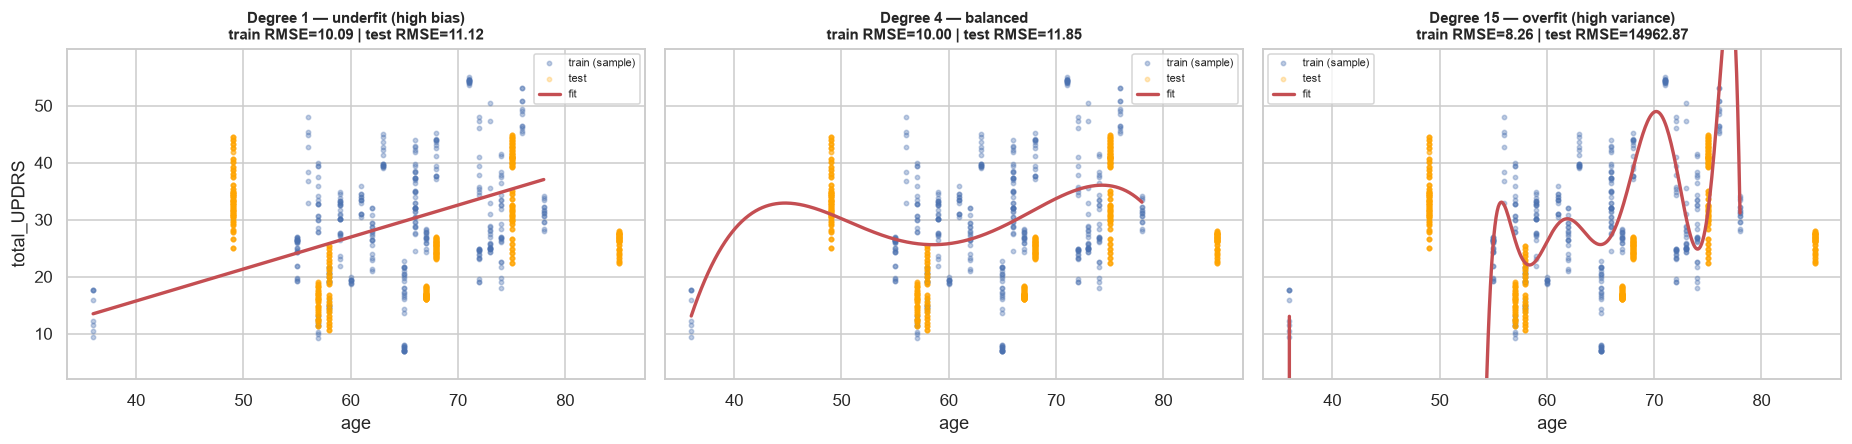

In [9]:
# 6.1 One-feature visual demo
sub = np.random.default_rng(SEED).choice(len(Xtr), size=min(400, len(Xtr)), replace=False)
xs = Xtr[[TOP1]].values; xg = np.linspace(xs.min(), xs.max(), 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, deg, title in zip(axes, [1, 4, 15], ["Degree 1 — underfit (high bias)", "Degree 4 — balanced", "Degree 15 — overfit (high variance)"]):
    m = poly_pipe(deg).fit(xs, ytr)
    ax.scatter(xs[sub], ytr[sub], s=8, alpha=.35, label="train (sample)")
    ax.scatter(Xte[[TOP1]].values, yte, s=8, alpha=.25, c="orange", label="test")
    ax.plot(xg, m.predict(xg), "r", lw=2.2, label="fit")
    r_tr = np.sqrt(mean_squared_error(ytr, m.predict(xs))); r_te = np.sqrt(mean_squared_error(yte, m.predict(Xte[[TOP1]].values)))
    ax.set_title(f"{title}\ntrain RMSE={r_tr:.2f} | test RMSE={r_te:.2f}", fontsize=10); ax.set_xlabel(TOP1); ax.legend(fontsize=7)
    ax.set_ylim(ytr.min()-5, ytr.max()+5)
axes[0].set_ylabel(TARGET); plt.tight_layout(); savefig("05_poly_single_feature_demo"); plt.show()

,n_terms,train_RMSE,cv_RMSE,cv_RMSE_sd,test_RMSE,train_R2,test_R2
degree,,,,,,,
1,5,9.903,10.261,1.708,11.424,0.193,-5.750000e-01
2,20,9.590,10.811,1.637,12.709,0.243,-9.490000e-01
3,55,9.298,15.313,5.295,13.761,0.288,-1.285000e+00
4,125,8.726,68.546,103.789,16.172,0.373,-2.156000e+00
5,251,8.453,270.626,460.159,80.672,0.412,-7.754100e+01
6,461,8.132,1473.501,2415.827,1470.390,0.456,-2.609128e+04
7,791,7.694,5801.384,6234.205,14449.120,0.513,-2.519589e+06
8,1286,6.636,141427.029,192637.506,340234.485,0.637,-1.397024e+09


>>> Degree selected by subject-wise CV: 1


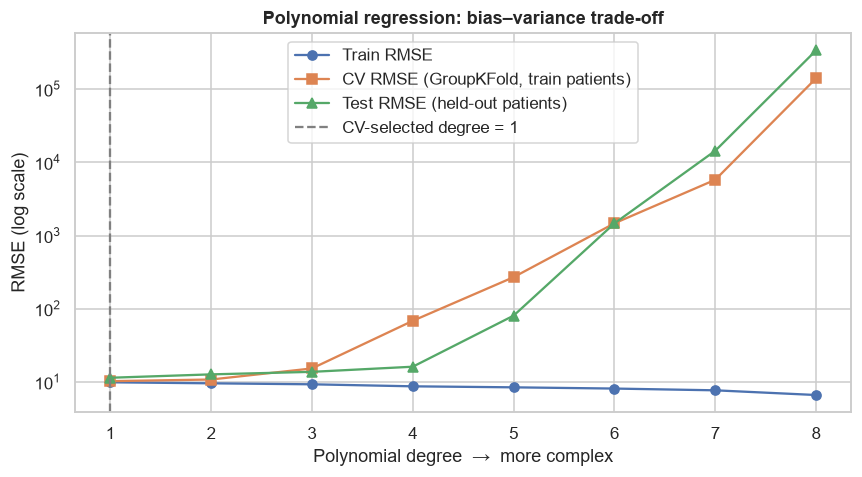

[Polynomial (deg 1, top-5 feats)]  test RMSE=11.424  R²=-0.575   (train RMSE=9.903, R²=0.193)


[Polynomial (deg 8, top-5 feats) [overfit]]  test RMSE=340234.485  R²=-1397023622.602   (train RMSE=6.636, R²=0.637)


In [10]:
# 6.2 Multi-feature study, degrees 1..8, GroupKFold CV on training patients
degrees = list(range(1, 9))
rec = []
for dgr in degrees:
    p = poly_pipe(dgr)
    cv_rmse = []
    for a, b in GKF.split(Xtr[TOP5], ytr, gtr):
        m = clone(p).fit(Xtr[TOP5].iloc[a], ytr[a])
        cv_rmse.append(np.sqrt(mean_squared_error(ytr[b], m.predict(Xtr[TOP5].iloc[b]))))
    m = clone(p).fit(Xtr[TOP5], ytr)
    n_terms = m.named_steps["poly"].n_output_features_
    rec.append({"degree": dgr, "n_terms": n_terms,
                "train_RMSE": np.sqrt(mean_squared_error(ytr, m.predict(Xtr[TOP5]))),
                "cv_RMSE": np.mean(cv_rmse), "cv_RMSE_sd": np.std(cv_rmse),
                "test_RMSE": np.sqrt(mean_squared_error(yte, m.predict(Xte[TOP5]))),
                "train_R2": r2_score(ytr, m.predict(Xtr[TOP5])), "test_R2": r2_score(yte, m.predict(Xte[TOP5]))})
poly_df = pd.DataFrame(rec).set_index("degree")
display(poly_df.round(3))

best_deg = int(poly_df["cv_RMSE"].idxmin())
print(f">>> Degree selected by subject-wise CV: {best_deg}")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(poly_df.index, poly_df["train_RMSE"], "o-", label="Train RMSE")
ax.plot(poly_df.index, poly_df["cv_RMSE"], "s-", label="CV RMSE (GroupKFold, train patients)")
ax.plot(poly_df.index, poly_df["test_RMSE"], "^-", label="Test RMSE (held-out patients)")
ax.axvline(best_deg, color="gray", ls="--", label=f"CV-selected degree = {best_deg}")
ax.set_yscale("log"); ax.set_xlabel("Polynomial degree  →  more complex"); ax.set_ylabel("RMSE (log scale)")
ax.set_title("Polynomial regression: bias–variance trade-off"); ax.legend(); plt.tight_layout(); savefig("06_poly_degree_curves"); plt.show()
poly_df.round(5).to_csv(f"{RES_DIR}/q2_poly_degree_study.csv")

pm = poly_pipe(best_deg).fit(Xtr[TOP5], ytr)
record(f"Polynomial (deg {best_deg}, top-5 feats)", pm, pm.predict(Xtr[TOP5]), pm.predict(Xte[TOP5]), {"degree": best_deg, "features": TOP5})
# Also record an explicit overfit example (highest degree) for the comparison table
pm_hi = poly_pipe(degrees[-1]).fit(Xtr[TOP5], ytr)
record(f"Polynomial (deg {degrees[-1]}, top-5 feats) [overfit]", pm_hi, pm_hi.predict(Xtr[TOP5]), pm_hi.predict(Xte[TOP5]), {"degree": degrees[-1]})

## 7. Model (c) — Ridge and Lasso, with the regularisation strength chosen by cross-validation
* **Ridge (L2):** minimise  MSE + α·‖w‖²₂ → shrinks all coefficients smoothly, handles correlated features by *sharing* weight between them; never exactly zero.
* **Lasso (L1):** minimise  MSE + α·‖w‖₁ → drives some coefficients **exactly to zero** (built-in feature selection); with groups of correlated features it tends to pick one and drop the rest.
* **α (regularisation strength):** α → 0 gives OLS (low bias, high variance); α → ∞ gives the constant mean model (high bias, low variance). The best α is the minimum of the **cross-validated** error curve.
* **CV scheme:** `GroupKFold(5)` over the *training patients* (so validation folds contain unseen patients, mimicking deployment). Scaling is inside the pipeline.

We also show the **1-standard-error choice** (largest α whose CV error is within 1 SE of the minimum — a more conservative, simpler model), for information only.

Tuning took 54.8s
Ridge: best α = 2683 (CV RMSE 10.681) | 1-SE α = 1e+04
Lasso: best α = 1.207 (CV RMSE 10.354) | 1-SE α = 10


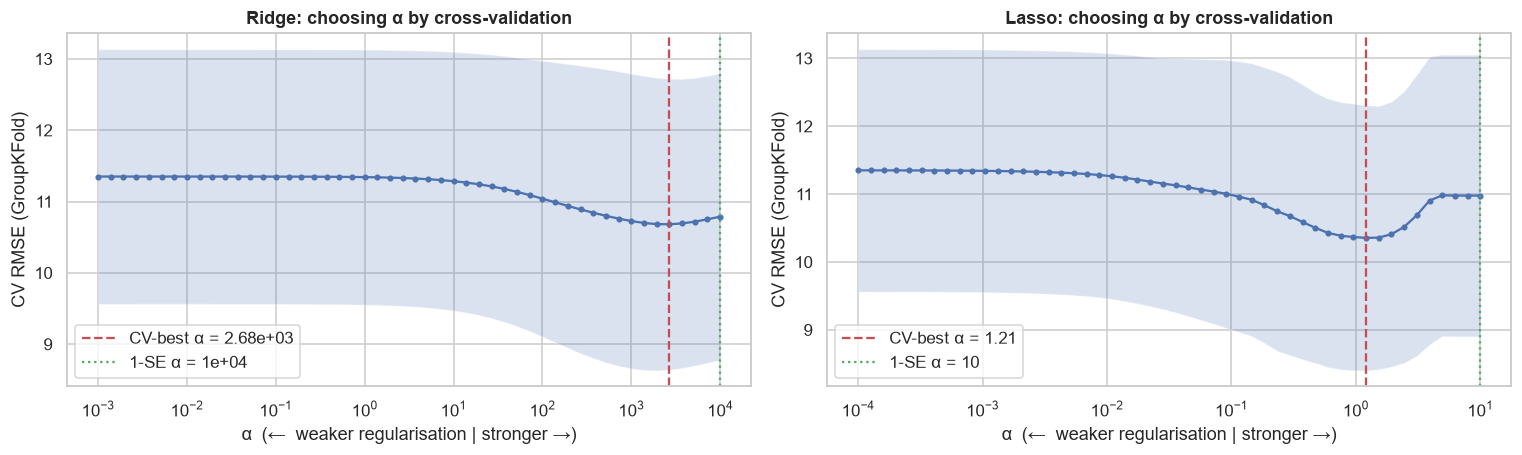

[Ridge (CV α)]  test RMSE=9.998  R²=-0.206   (train RMSE=9.969, R²=0.182)
[Lasso (CV α)]  test RMSE=10.296  R²=-0.279   (train RMSE=10.104, R²=0.159)


In [11]:
def tune_alpha(base_pipe, alphas, X, y, groups):
    grid = GridSearchCV(base_pipe, {"reg__alpha": alphas}, cv=GKF, scoring="neg_mean_squared_error", n_jobs=-1, refit=True)
    grid.fit(X, y, groups=groups)
    fold_rmse = np.sqrt(-np.column_stack([grid.cv_results_[f"split{i}_test_score"] for i in range(GKF.n_splits)]))
    mean, sd = fold_rmse.mean(1), fold_rmse.std(1)
    i_min = int(np.argmin(mean))
    se = sd[i_min] / np.sqrt(GKF.n_splits)
    ok = np.where(mean <= mean[i_min] + se)[0]
    alpha_1se = np.asarray(alphas)[ok].max()
    return grid, np.asarray(alphas), mean, sd, grid.best_params_["reg__alpha"], alpha_1se

lin_pipe = lambda reg: Pipeline([("s", StandardScaler()), ("reg", reg)])
ridge_alphas = np.logspace(-3, 4, 50)
lasso_alphas = np.logspace(-4, 1, 50)
t0 = time.time()
ridge_gs, ra, r_mean, r_sd, ridge_alpha, ridge_alpha_1se = tune_alpha(lin_pipe(Ridge(random_state=SEED)), ridge_alphas, Xtr, ytr, gtr)
lasso_gs, la, l_mean, l_sd, lasso_alpha, lasso_alpha_1se = tune_alpha(lin_pipe(Lasso(max_iter=50000, random_state=SEED)), lasso_alphas, Xtr, ytr, gtr)
print(f"Tuning took {time.time()-t0:.1f}s")
print(f"Ridge: best α = {ridge_alpha:.4g} (CV RMSE {r_mean.min():.3f}) | 1-SE α = {ridge_alpha_1se:.4g}")
print(f"Lasso: best α = {lasso_alpha:.4g} (CV RMSE {l_mean.min():.3f}) | 1-SE α = {lasso_alpha_1se:.4g}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, a, m, s, best, one, nm in [(axes[0], ra, r_mean, r_sd, ridge_alpha, ridge_alpha_1se, "Ridge"), (axes[1], la, l_mean, l_sd, lasso_alpha, lasso_alpha_1se, "Lasso")]:
    ax.plot(a, m, "o-", ms=3); ax.fill_between(a, m - s, m + s, alpha=.2)
    ax.axvline(best, color="r", ls="--", label=f"CV-best α = {best:.3g}"); ax.axvline(one, color="g", ls=":", label=f"1-SE α = {one:.3g}")
    ax.set_xscale("log"); ax.set_xlabel("α  (←  weaker regularisation | stronger →)"); ax.set_ylabel("CV RMSE (GroupKFold)")
    ax.set_title(f"{nm}: choosing α by cross-validation"); ax.legend()
plt.tight_layout(); savefig("07_ridge_lasso_cv_curves"); plt.show()

ridge_best, lasso_best = ridge_gs.best_estimator_, lasso_gs.best_estimator_
record("Ridge (CV α)", ridge_best, ridge_best.predict(Xtr), ridge_best.predict(Xte), {"alpha": float(ridge_alpha)})
record("Lasso (CV α)", lasso_best, lasso_best.predict(Xtr), lasso_best.predict(Xte), {"alpha": float(lasso_alpha)})

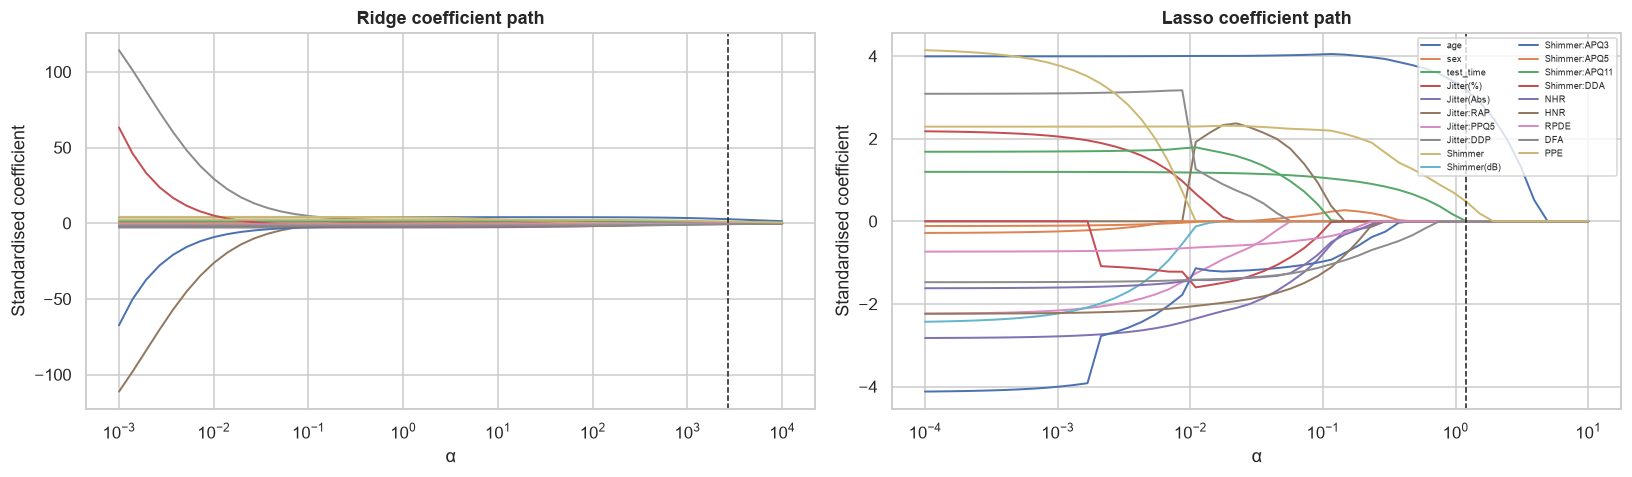

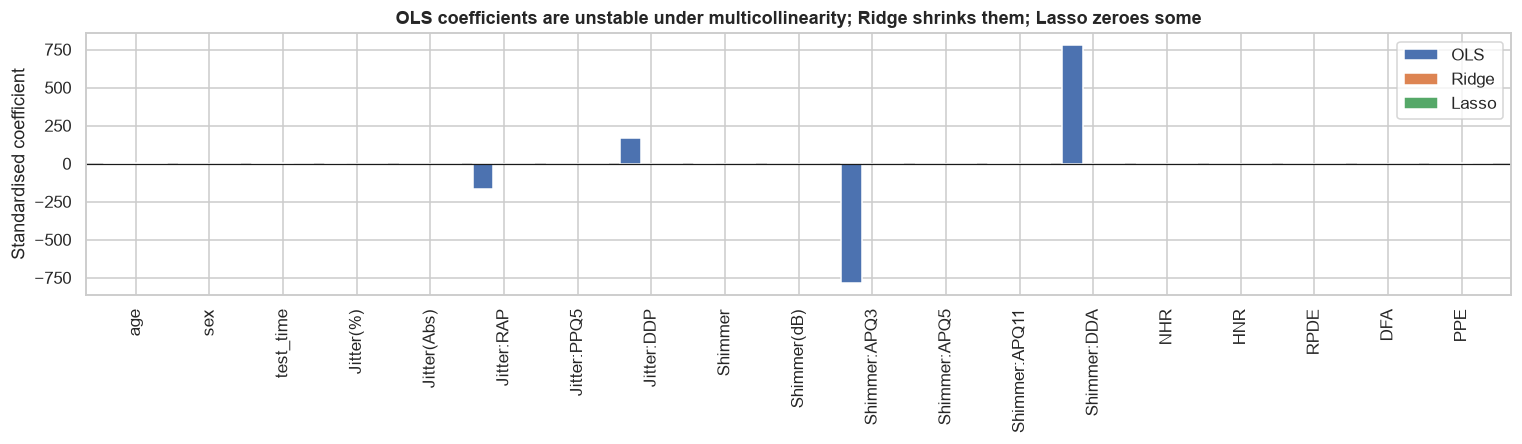

Lasso set 17 of 19 coefficients to exactly zero: ['sex', 'test_time', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA']
Largest |OLS| coefficients: {'Shimmer:APQ3': 783.72, 'Shimmer:DDA': 779.58, 'Jitter:DDP': 169.75, 'Jitter:RAP': 166.64}


In [12]:
# Coefficient paths + comparison of OLS / Ridge / Lasso coefficients (standardised features → comparable)
Zs = StandardScaler().fit_transform(Xtr)
ridge_path = np.array([Ridge(alpha=a).fit(Zs, ytr).coef_ for a in ra])
lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(Zs, ytr).coef_ for a in la])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, a, path, nm, best in [(axes[0], ra, ridge_path, "Ridge", ridge_alpha), (axes[1], la, lasso_path, "Lasso", lasso_alpha)]:
    for j, f in enumerate(FEATURES):
        ax.plot(a, path[:, j], lw=1.3, label=f)
    ax.axvline(best, color="k", ls="--", lw=1); ax.set_xscale("log"); ax.set_xlabel("α"); ax.set_ylabel("Standardised coefficient"); ax.set_title(f"{nm} coefficient path")
axes[1].legend(fontsize=6, ncol=2, loc="upper right")
plt.tight_layout(); savefig("08_coefficient_paths"); plt.show()

coef = pd.DataFrame({"OLS": ols.coef_, "Ridge": ridge_best.named_steps["reg"].coef_, "Lasso": lasso_best.named_steps["reg"].coef_}, index=FEATURES)
coef.plot(kind="bar", figsize=(14, 4.2), width=.85); plt.axhline(0, color="k", lw=.8); plt.ylabel("Standardised coefficient")
plt.title("OLS coefficients are unstable under multicollinearity; Ridge shrinks them; Lasso zeroes some"); plt.tight_layout(); savefig("09_coefficient_comparison"); plt.show()
zero = coef.index[coef["Lasso"] == 0].tolist()
print(f"Lasso set {len(zero)} of {len(FEATURES)} coefficients to exactly zero:", zero)
print("Largest |OLS| coefficients:", coef["OLS"].abs().sort_values(ascending=False).head(4).round(2).to_dict())
coef.round(5).to_csv(f"{RES_DIR}/q2_coefficients.csv")

### 7.1 Regularisation as the *cure* for polynomial overfitting
Degree-2 polynomial on **all** features (209 terms): plain OLS vs Ridge vs Lasso, with α again chosen by GroupKFold CV. This directly answers "use cross-validation to select the regularisation parameter" in the setting where it matters most.

Poly-2 Ridge best α = 1e+05 | Lasso best α = 2.26


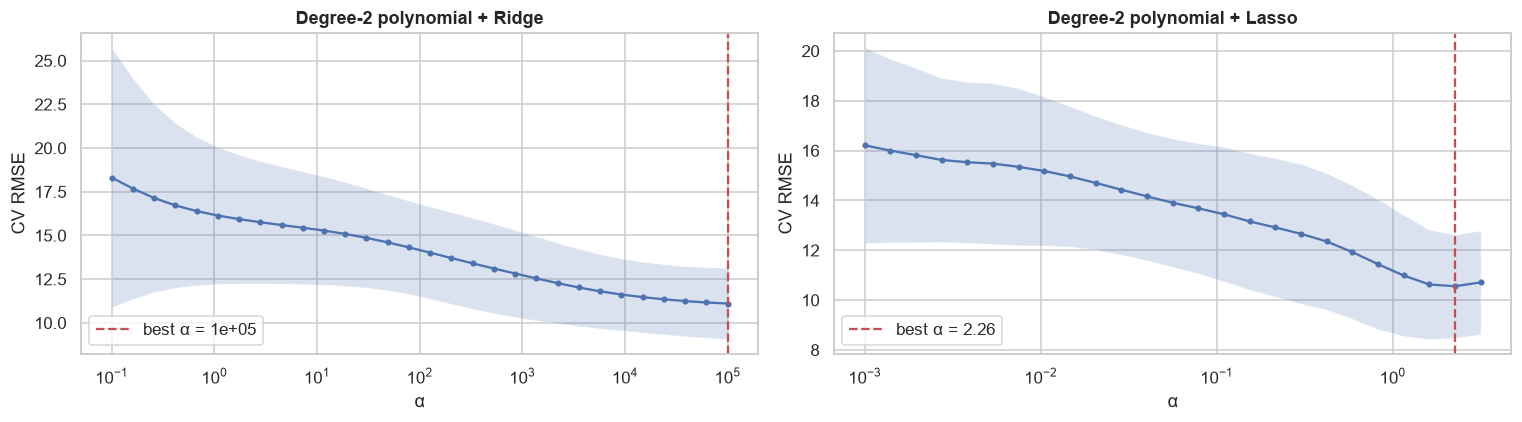

[Poly deg 2 (all feats) OLS]  test RMSE=35.111  R²=-13.878   (train RMSE=8.181, R²=0.449)
[Poly deg 2 + Ridge]  test RMSE=9.342  R²=-0.053   (train RMSE=10.789, R²=0.042)
[Poly deg 2 + Lasso]  test RMSE=9.779  R²=-0.154   (train RMSE=10.344, R²=0.119)
Lasso keeps 1 of 209 polynomial terms


In [13]:
def poly_reg_pipe(deg, reg):
    return Pipeline([("s1", StandardScaler()), ("poly", PolynomialFeatures(deg, include_bias=False)), ("s2", StandardScaler()), ("reg", reg)])

DEG = 2
ols_p = poly_reg_pipe(DEG, LinearRegression()).fit(Xtr, ytr)
ridge_p_gs, rpa, rp_mean, rp_sd, rp_alpha, _ = tune_alpha(poly_reg_pipe(DEG, Ridge(random_state=SEED)), np.logspace(-1, 5, 30), Xtr, ytr, gtr)
lasso_p_gs, lpa, lp_mean, lp_sd, lp_alpha, _ = tune_alpha(poly_reg_pipe(DEG, Lasso(max_iter=50000, random_state=SEED)), np.logspace(-3, 0.5, 25), Xtr, ytr, gtr)
print(f"Poly-{DEG} Ridge best α = {rp_alpha:.4g} | Lasso best α = {lp_alpha:.4g}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, a, m, s, best, nm in [(axes[0], rpa, rp_mean, rp_sd, rp_alpha, "Ridge"), (axes[1], lpa, lp_mean, lp_sd, lp_alpha, "Lasso")]:
    ax.plot(a, m, "o-", ms=3); ax.fill_between(a, m - s, m + s, alpha=.2); ax.axvline(best, color="r", ls="--", label=f"best α = {best:.3g}")
    ax.set_xscale("log"); ax.set_xlabel("α"); ax.set_ylabel("CV RMSE"); ax.set_title(f"Degree-{DEG} polynomial + {nm}"); ax.legend()
plt.tight_layout(); savefig("10_poly_regularisation_cv"); plt.show()

record(f"Poly deg {DEG} (all feats) OLS", ols_p, ols_p.predict(Xtr), ols_p.predict(Xte))
rb, lb = ridge_p_gs.best_estimator_, lasso_p_gs.best_estimator_
record(f"Poly deg {DEG} + Ridge", rb, rb.predict(Xtr), rb.predict(Xte), {"alpha": float(rp_alpha)})
record(f"Poly deg {DEG} + Lasso", lb, lb.predict(Xtr), lb.predict(Xte), {"alpha": float(lp_alpha), "nonzero_terms": int((lb.named_steps["reg"].coef_ != 0).sum())})
print("Lasso keeps", int((lb.named_steps["reg"].coef_ != 0).sum()), "of", lb.named_steps["reg"].coef_.size, "polynomial terms")

## 8. Comparison of all regression models (held-out patients)

TEST metrics (held-out patients)


,MSE,RMSE,R2,R (Pearson)
Baseline (mean),8.962400e+01,9.4670,-8.160000e-02,NaN
Linear regression (GD),1.307405e+02,11.4342,-5.778000e-01,0.1195
Linear regression (closed form),1.309058e+02,11.4414,-5.798000e-01,0.1187
"Polynomial (deg 1, top-5 feats)",1.304986e+02,11.4236,-5.749000e-01,0.1044
"Polynomial (deg 8, top-5 feats) [overfit]",1.157595e+11,340234.4847,-1.397024e+09,0.0495
Ridge (CV α),9.995570e+01,9.9978,-2.063000e-01,0.1359
Lasso (CV α),1.060178e+02,10.2965,-2.795000e-01,0.1005
Poly deg 2 (all feats) OLS,1.232790e+03,35.1111,-1.387770e+01,0.0361
Poly deg 2 + Ridge,8.726570e+01,9.3416,-5.320000e-02,0.1560
Poly deg 2 + Lasso,9.562430e+01,9.7788,-1.540000e-01,0.0876


TRAIN metrics


,MSE,RMSE,R2,R (Pearson)
Baseline (mean),121.4698,11.0213,0.0000,NaN
Linear regression (GD),93.9449,9.6925,0.2266,0.4760
Linear regression (closed form),93.8967,9.6900,0.2270,0.4764
"Polynomial (deg 1, top-5 feats)",98.0619,9.9026,0.1927,0.4390
"Polynomial (deg 8, top-5 feats) [overfit]",44.0380,6.6361,0.6375,0.7984
Ridge (CV α),99.3846,9.9692,0.1818,0.4575
Lasso (CV α),102.1007,10.1045,0.1595,0.4177
Poly deg 2 (all feats) OLS,66.9332,8.1813,0.4490,0.6701
Poly deg 2 + Ridge,116.3966,10.7887,0.0418,0.3708
Poly deg 2 + Lasso,106.9928,10.3437,0.1192,0.4015


Over/under-fitting view


,Train RMSE,Test RMSE,Test−Train RMSE,Train R2,Test R2
Baseline (mean),11.021,9.467,-1.554,0.000,-8.200000e-02
Linear regression (GD),9.693,11.434,1.742,0.227,-5.780000e-01
Linear regression (closed form),9.690,11.441,1.751,0.227,-5.800000e-01
"Polynomial (deg 1, top-5 feats)",9.903,11.424,1.521,0.193,-5.750000e-01
"Polynomial (deg 8, top-5 feats) [overfit]",6.636,340234.485,340227.849,0.637,-1.397024e+09
Ridge (CV α),9.969,9.998,0.029,0.182,-2.060000e-01
Lasso (CV α),10.104,10.296,0.192,0.159,-2.790000e-01
Poly deg 2 (all feats) OLS,8.181,35.111,26.930,0.449,-1.387800e+01
Poly deg 2 + Ridge,10.789,9.342,-1.447,0.042,-5.300000e-02
Poly deg 2 + Lasso,10.344,9.779,-0.565,0.119,-1.540000e-01


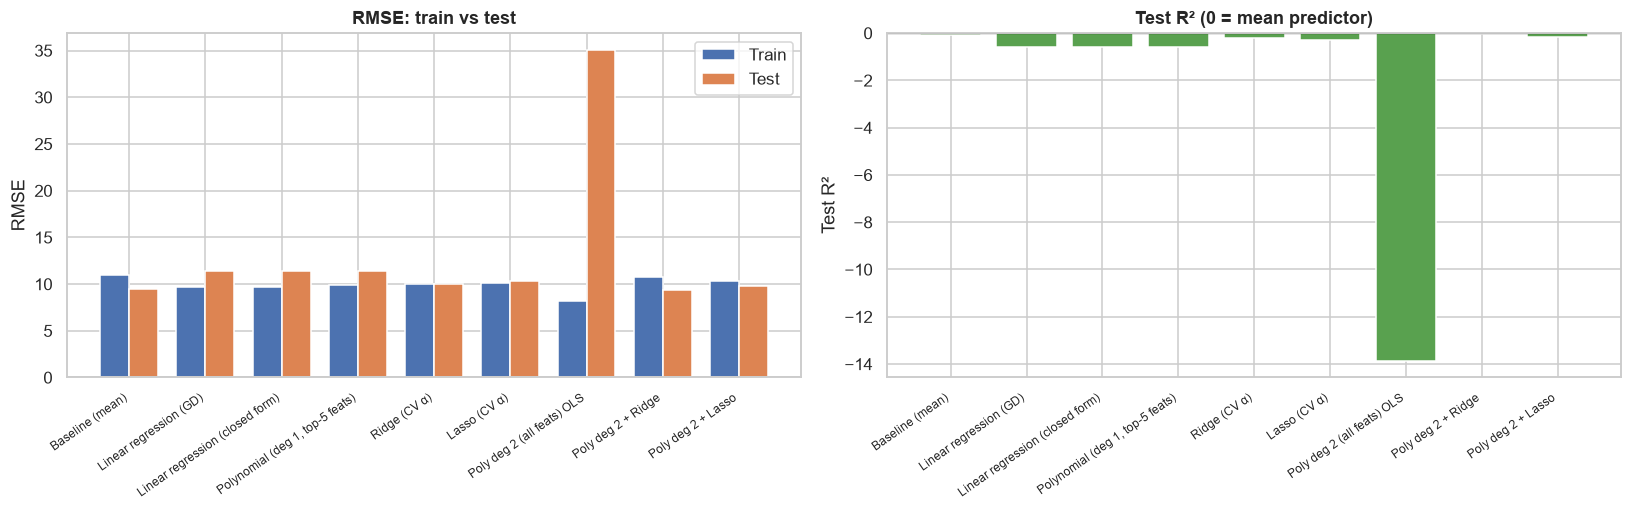

>>> Lowest test RMSE: Poly deg 2 + Ridge  (RMSE=9.342, R²=-0.053)


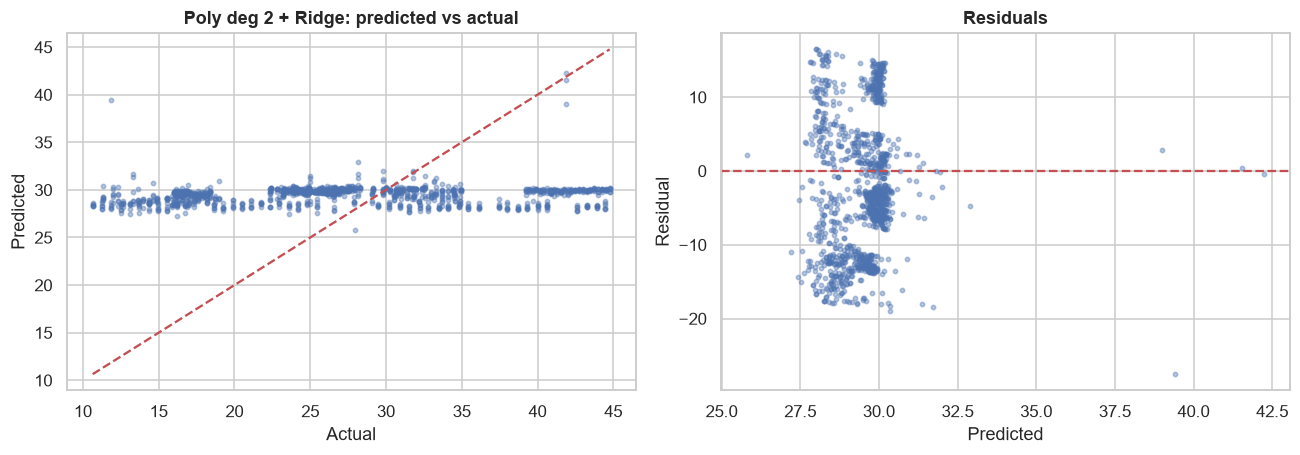

In [14]:
order = list(ROWS)
test_tbl = pd.DataFrame({n: ROWS[n]["test"] for n in order}).T
train_tbl = pd.DataFrame({n: ROWS[n]["train"] for n in order}).T
print("TEST metrics (held-out patients)"); display(test_tbl.round(4))
print("TRAIN metrics"); display(train_tbl.round(4))
gap = pd.DataFrame({"Train RMSE": train_tbl["RMSE"], "Test RMSE": test_tbl["RMSE"], "Test−Train RMSE": test_tbl["RMSE"] - train_tbl["RMSE"],
                    "Train R2": train_tbl["R2"], "Test R2": test_tbl["R2"]})
print("Over/under-fitting view"); display(gap.round(3))

show = [n for n in order if "[overfit]" not in n]                # keep the plot readable
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(show)); w = .38
axes[0].bar(x - w/2, train_tbl.loc[show, "RMSE"], w, label="Train"); axes[0].bar(x + w/2, test_tbl.loc[show, "RMSE"], w, label="Test")
axes[0].set_xticks(x); axes[0].set_xticklabels(show, rotation=35, ha="right", fontsize=8); axes[0].set_ylabel("RMSE"); axes[0].set_title("RMSE: train vs test"); axes[0].legend()
axes[1].bar(x, test_tbl.loc[show, "R2"], color="#59A14F"); axes[1].axhline(0, color="k", lw=.8)
axes[1].set_xticks(x); axes[1].set_xticklabels(show, rotation=35, ha="right", fontsize=8); axes[1].set_ylabel("Test R²"); axes[1].set_title("Test R² (0 = mean predictor)")
plt.tight_layout(); savefig("11_model_comparison"); plt.show()

best_name = test_tbl.drop(index=[n for n in order if "[overfit]" in n])["RMSE"].idxmin()
print(f">>> Lowest test RMSE: {best_name}  (RMSE={test_tbl.loc[best_name,'RMSE']:.3f}, R²={test_tbl.loc[best_name,'R2']:.3f})")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
pr = ROWS[best_name]["pred_test"]
axes[0].scatter(yte, pr, s=8, alpha=.4); lim = [min(yte.min(), pr.min()), max(yte.max(), pr.max())]; axes[0].plot(lim, lim, "r--")
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted"); axes[0].set_title(f"{best_name}: predicted vs actual")
axes[1].scatter(pr, yte - pr, s=8, alpha=.4); axes[1].axhline(0, color="r", ls="--"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals")
plt.tight_layout(); savefig("12_best_model_diagnostics"); plt.show()

## 9. Why the subject-wise split matters (leakage experiment)
Same models, same α, but evaluated on a **random-row** test set where the same patients also appear in training. We add a Random Forest (not required by the brief) purely because flexible models exploit this leakage most strongly by "recognising" patients.

RMSE                        \
Split                    Random rows (leaky) Subject-wise (honest)   
Model                                                                
Lasso (CV α)                          10.018                10.296   
Polynomial deg 1 (top-5)               9.909                11.424   
Random Forest (extra)                  1.581                13.396   
Ridge (CV α)                           9.760                 9.998   

                                          R2                        
Split                    Random rows (leaky) Subject-wise (honest)  
Model                                                               
Lasso (CV α)                           0.094                -0.279  
Polynomial deg 1 (top-5)               0.114                -0.575  
Random Forest (extra)                  0.977                -1.166  
Ridge (CV α)                           0.140                -0.206

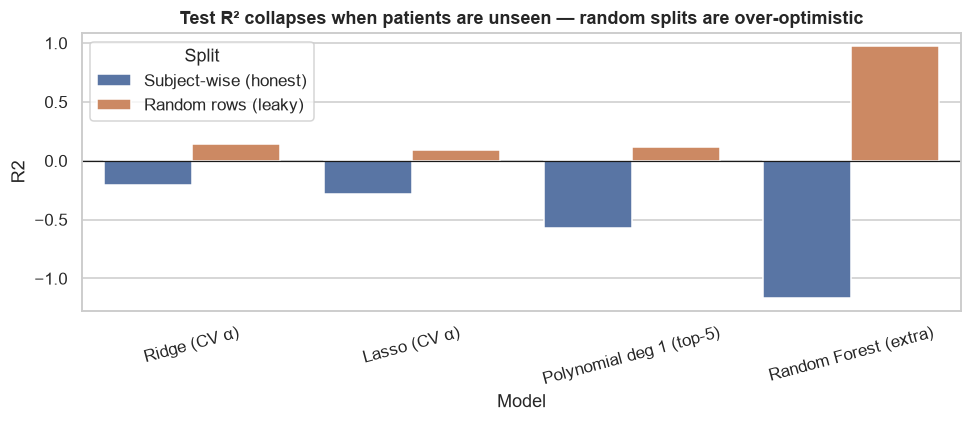

In [15]:
def eval_split(model, tr, te):
    m = clone(model).fit(X_all.iloc[tr], y_all.iloc[tr]); p = m.predict(X_all.iloc[te])
    return reg_metrics(y_all.iloc[te], p)

leak_models = {"Ridge (CV α)": lin_pipe(Ridge(alpha=ridge_alpha)),
               "Lasso (CV α)": lin_pipe(Lasso(alpha=lasso_alpha, max_iter=50000)),
               f"Polynomial deg {best_deg} (top-5)": None,
               "Random Forest (extra)": RandomForestRegressor(n_estimators=200, min_samples_leaf=1, n_jobs=-1, random_state=SEED)}
rows = []
for n, m in leak_models.items():
    for split_name, (tr, te) in {"Subject-wise (honest)": (tr_idx, te_idx), "Random rows (leaky)": (rtr_idx, rte_idx)}.items():
        if m is None:
            mm = poly_pipe(best_deg).fit(X_all.iloc[tr][TOP5], y_all.iloc[tr]); met = reg_metrics(y_all.iloc[te], mm.predict(X_all.iloc[te][TOP5]))
        else:
            met = eval_split(m, tr, te)
        rows.append({"Model": n, "Split": split_name, **met})
leak = pd.DataFrame(rows)
display(leak.pivot(index="Model", columns="Split", values=["RMSE", "R2"]).round(3))
leak.round(5).to_csv(f"{RES_DIR}/q2_leakage_experiment.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=leak, x="Model", y="R2", hue="Split", ax=ax); ax.axhline(0, color="k", lw=.8)
ax.set_title("Test R² collapses when patients are unseen — random splits are over-optimistic"); plt.xticks(rotation=15); plt.tight_layout(); savefig("13_leakage_experiment"); plt.show()

## 10. Robustness: 5-fold subject-wise cross-validation over all 42 patients
One test split of ~8 patients is noisy. Here each model (with the hyper-parameters found above, *not re-tuned*, so this is slightly optimistic) is evaluated on 5 different patient-disjoint folds; we report mean ± sd.

In [16]:
final_models = {"Baseline (mean)": DummyRegressor(strategy="mean"),
                "Linear regression (OLS)": lin_pipe(LinearRegression()),
                "Ridge (CV α)": lin_pipe(Ridge(alpha=ridge_alpha)),
                "Lasso (CV α)": lin_pipe(Lasso(alpha=lasso_alpha, max_iter=50000)),
                f"Poly deg {DEG} + Ridge": poly_reg_pipe(DEG, Ridge(alpha=rp_alpha)),
                f"Poly deg {DEG} + Lasso": poly_reg_pipe(DEG, Lasso(alpha=lp_alpha, max_iter=50000))}
cvrows = []
for n, m in final_models.items():
    fm = []
    for a, b in GKF.split(X_all, y_all, groups_all):
        mm = clone(m).fit(X_all.iloc[a], y_all.iloc[a]); fm.append(reg_metrics(y_all.iloc[b], mm.predict(X_all.iloc[b])))
    f = pd.DataFrame(fm)
    cvrows.append({"Model": n, "RMSE mean": f["RMSE"].mean(), "RMSE sd": f["RMSE"].std(), "R2 mean": f["R2"].mean(), "R2 sd": f["R2"].std()})
cv_tbl = pd.DataFrame(cvrows).set_index("Model"); display(cv_tbl.round(3))
cv_tbl.round(5).to_csv(f"{RES_DIR}/q2_groupkfold_robustness.csv")

,RMSE mean,RMSE sd,R2 mean,R2 sd
Model,,,,
Baseline (mean),10.920,1.116,-0.214,0.304
Linear regression (OLS),11.253,1.459,-0.308,0.392
Ridge (CV α),10.682,1.370,-0.159,0.280
Lasso (CV α),10.742,1.159,-0.172,0.274
Poly deg 2 + Ridge,11.140,1.339,-0.256,0.287
Poly deg 2 + Lasso,11.179,1.099,-0.265,0.256


## 11. Reading guide for the written discussion
* **Under/overfitting** — `05_poly_single_feature_demo` (picture), `06_poly_degree_curves` (train error keeps falling with degree while CV/test error rises → variance), the *[overfit]* row and the degree-2 OLS row in the comparison table vs. their regularised versions.
* **Choosing α** — `07_ridge_lasso_cv_curves`: left side (tiny α) = high variance; right side (huge α) = high bias; red line = CV optimum. Mention GroupKFold and why plain K-fold would have been optimistic.
* **Ridge vs Lasso** — `08/09` coefficient plots: Ridge splits weight across correlated features; Lasso zeroes some (list them from the output).
* **GD** — it reaches the OLS optimum (compare MSEs), requires scaling and a learning rate below 2/λ_max; η too large → divergence (`03_gd_learning_rates_and_scaling`).
* **Honest conclusion** — compare every model to the mean baseline; if test R² is low, say that voice features + demographics explain only part of UPDRS variability *between unseen patients* and discuss `13_leakage_experiment`.

In [17]:
# ---------------------------------------------------------------------------
# Save everything the report needs
# ---------------------------------------------------------------------------
test_tbl.round(6).to_csv(f"{RES_DIR}/q2_metrics_test.csv"); train_tbl.round(6).to_csv(f"{RES_DIR}/q2_metrics_train.csv"); gap.round(6).to_csv(f"{RES_DIR}/q2_overfitting_summary.csv")
with open(f"{RES_DIR}/q2_params.json", "w") as f:
    json.dump({"data_source": source, "target": TARGET, "features": FEATURES, "n_train_rows": int(len(Xtr)), "n_test_rows": int(len(Xte)),
               "n_train_patients": int(len(set(gtr))), "n_test_patients": int(len(set(gte))),
               "ridge_alpha": float(ridge_alpha), "lasso_alpha": float(lasso_alpha), "poly_best_degree": best_deg, "poly_top5": TOP5,
               "poly2_ridge_alpha": float(rp_alpha), "poly2_lasso_alpha": float(lp_alpha), "gd_lr": 0.1, "gd_iterations": int(gd.n_iter_),
               "lasso_zeroed_features": zero, "best_model_lowest_test_rmse": best_name}, f, indent=2)
print("Saved metrics to", os.path.abspath(RES_DIR), "and figures to", os.path.abspath(FIG_DIR))

Saved metrics to C:\Users\user\OneDrive\Desktop\ml_assignment\results and figures to C:\Users\user\OneDrive\Desktop\ml_assignment\figures\q2
